# EDA — Wall-Following Robot Navigation (24 sensores)

Análise exploratória de `sensor_readings_24.data`: 24 sensores ultrassônicos (US1 = frente, numeração no sentido horário) e 4 classes de movimento.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sensores = [f"US{i}" for i in range(1, 25)]
df = pd.read_csv("wall+following+robot+navigation+data/sensor_readings_24.data",
                 header=None, names=sensores + ["classe"])
print(df.shape)
df.head()

(5456, 25)


,US1,US2,US3,US4,US5,US6,US7,US8,US9,US10,...,US16,US17,US18,US19,US20,US21,US22,US23,US24,classe
0,0.438,0.498,3.625,3.645,5.0,2.918,5.0,2.351,2.332,2.643,...,0.593,0.502,0.493,0.504,0.445,0.431,0.444,0.440,0.429,Slight-Right-Turn
1,0.438,0.498,3.625,3.648,5.0,2.918,5.0,2.637,2.332,2.649,...,0.592,0.502,0.493,0.504,0.449,0.431,0.444,0.443,0.429,Slight-Right-Turn
2,0.438,0.498,3.625,3.629,5.0,2.918,5.0,2.637,2.334,2.643,...,0.593,0.502,0.493,0.504,0.449,0.431,0.444,0.446,0.429,Slight-Right-Turn
3,0.437,0.501,3.625,3.626,5.0,2.918,5.0,2.353,2.334,2.642,...,0.593,0.502,0.493,0.504,0.449,0.431,0.444,0.444,0.429,Slight-Right-Turn
4,0.438,0.498,3.626,3.629,5.0,2.918,5.0,2.640,2.334,2.639,...,0.592,0.502,0.493,0.504,0.449,0.431,0.444,0.441,0.429,Slight-Right-Turn


## Qualidade dos dados

In [2]:
print("Valores ausentes:", df.isna().sum().sum())
print("Linhas duplicadas:", df.duplicated().sum())

Valores ausentes: 0
Linhas duplicadas: 0


## Distribuição das classes

,n,%
classe,,
Move-Forward,2205,40.4
Sharp-Right-Turn,2097,38.4
Slight-Right-Turn,826,15.1
Slight-Left-Turn,328,6.0


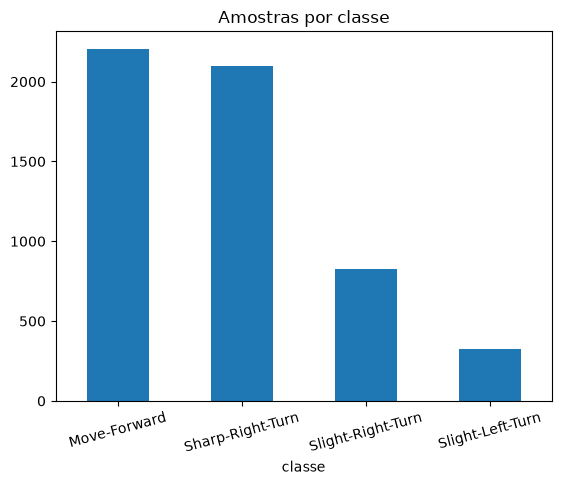

In [3]:
contagem = df["classe"].value_counts()
display(pd.DataFrame({"n": contagem, "%": (100 * contagem / len(df)).round(1)}))
contagem.plot.bar(rot=15, title="Amostras por classe")
plt.show()

## Estatística descritiva

In [4]:
df[sensores].describe().T

,count,mean,std,min,25%,50%,75%,max
US1,5456.0,1.471617,0.802801,0.400,0.92100,1.3350,1.81400,5.000
US2,5456.0,2.327043,1.410146,0.437,1.36200,1.9045,2.68150,5.025
US3,5456.0,2.489347,1.247435,0.470,1.53875,2.0640,2.73925,5.029
US4,5456.0,2.796501,1.309368,0.833,1.73100,2.4580,4.09350,5.017
US5,5456.0,2.958552,1.339225,1.120,1.77400,2.6670,4.31450,5.000
US6,5456.0,2.893073,1.282575,1.114,1.78575,2.6825,3.83525,5.005
US7,5456.0,3.351113,1.413692,1.122,1.93075,3.2255,5.00000,5.008
US8,5456.0,2.540397,1.111554,0.859,1.61800,2.1720,3.19300,5.087
US9,5456.0,3.125621,1.356965,0.836,1.79975,2.8020,5.00000,5.000
US10,5456.0,2.832386,1.307843,0.810,1.63600,2.6790,3.52625,5.022


## Distribuição por sensor

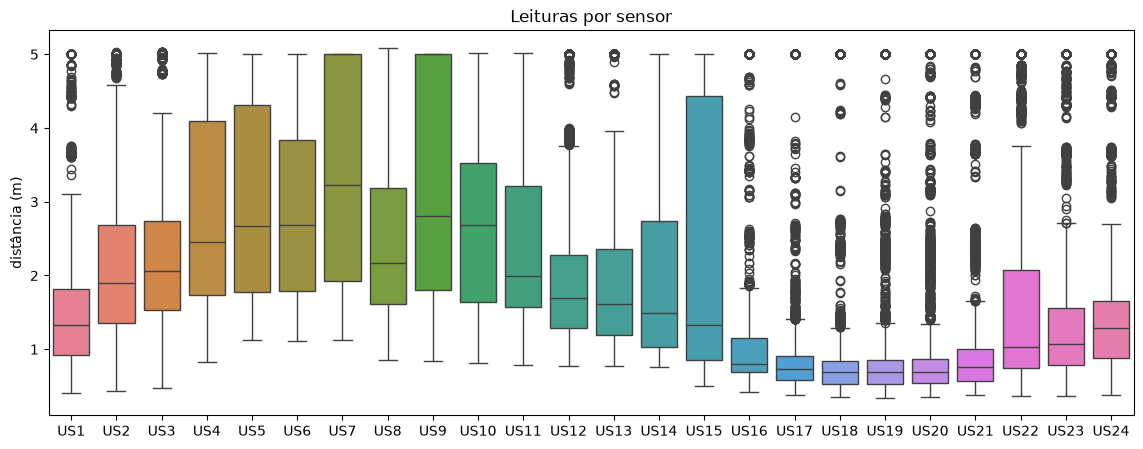

% de leituras saturadas (5.0 m) por sensor:
US1      1.2
US2     16.1
US3     14.9
US4     19.5
US5     22.6
US6     19.2
US7     35.6
US8      7.6
US9     27.0
US10    19.5
US11    19.2
US12    10.9
US13    16.5
US14    21.1
US15    24.2
US16     6.1
US17     4.5
US18     3.7
US19     6.4
US20     5.9
US21     2.0
US22    13.5
US23     8.4
US24     6.7


In [5]:
plt.figure(figsize=(14, 5))
sns.boxplot(data=df[sensores])
plt.ylabel("distância (m)")
plt.title("Leituras por sensor")
plt.show()
print("% de leituras saturadas (5.0 m) por sensor:")
print((100 * (df[sensores] >= 5.0).mean()).round(1).to_string())

## Correlação entre sensores

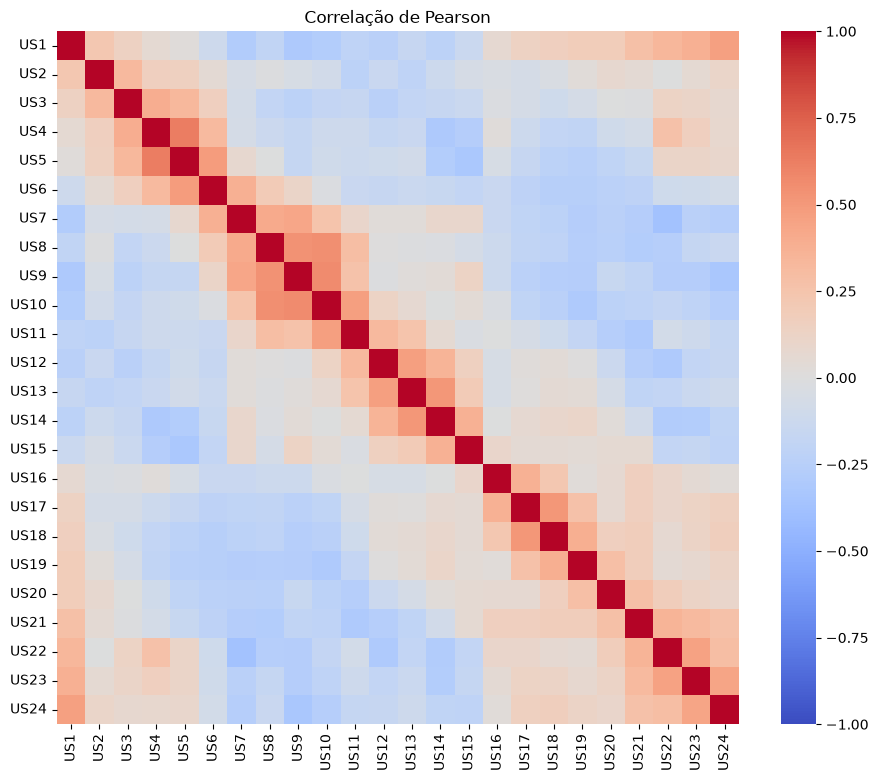

In [6]:
plt.figure(figsize=(11, 9))
sns.heatmap(df[sensores].corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlação de Pearson")
plt.show()

## Resumo

- **5456 amostras × 24 sensores**, sem valores ausentes nem linhas duplicadas. Todas as variáveis estão na mesma unidade (metros), entre ~0,34 m e ~5,0 m.
- **Classes desbalanceadas**: Move-Forward 40,4%, Sharp-Right-Turn 38,4%, Slight-Right-Turn 15,1%, Slight-Left-Turn 6,0% (328 amostras). Mesmo a menor classe tem bem mais amostras que dimensões (24).
- **Saturação em 5,0 m** (alcance máximo do sensor): até 35,6% das leituras do US7 e mais de 20% em vários sensores do lado esquerdo e de trás. Isso deixa as distribuições assimétricas, com um acúmulo de valores no limite superior.
- **Lados assimétricos**: os sensores do lado direito (US16–US21) têm medianas pequenas (~0,7 m), já que o robô segue a parede pela direita. Os sensores da frente, da esquerda e de trás leem distâncias maiores e mais variáveis.
- **Correlação moderada**: nenhum par de sensores tem |r| > 0,7. O maior valor fica entre vizinhos (US4–US5, r ≈ 0,63), e não há redundância forte entre variáveis.